Name:Swaroop NaikRoll:23102A0001

#Mini Project: Image Recognition and Classification with Keras in R**Problem statement:** Build a complete image classification pipeline in R that tells **aeroplanesapart from cars**. Twelve JPEG images (6 planes, 6 cars) of different sizes are read into R with the`EBImage` package, resized to a common 28x28, reshaped into feature vectors, and used to train afully connected neural network in `keras3` with TensorFlow as the backend. The model is thenevaluated on both the training images and two held-out test images, with confusion matrices andpredicted probabilities, and the misclassified pictures are displayed to see what the network gotwrong.**Dataset:** 12 JPEG images collected from an image search - `p1.jpg` ... `p6.jpg` (aeroplanes,class **0**) and `c1.jpg` ... `c6.jpg` (cars, class **1**). They arrive at different resolutions(from 461x433 up to 5000x3333), which is exactly why the resize step is needed. Images 1-5 and 7-11are used for training (10 images) and images 6 and 12 are held out for testing (1 plane, 1 car).**Reference:** *Image Recognition & Classification with Keras in R | TensorFlow for MachineIntelligence by Google* - Dr. Bharatendra Rai, https://youtu.be/iExh0qj2Ouo(R code: https://github.com/bkrai/DeepLearningR)The notebook follows the video's steps in the same order:| Time | Step | Section ||---|---|---|| 0:00 | Load Packages | 1 || 0:29 | Read Images | 2 || 4:08 | Explore | 3 || 6:16 | Resize | 4 || 7:23 | Reshape | 5 || 8:45 | Row Bind | 6 || 11:49 | One Hot Encoding | 7 || 12:42 | Create Model | 8 || 16:02 | Compile | 9 || 16:38 | Fit Model | 10 || 18:49 | Evaluation and Prediction (train data) | 11 || 22:20 | Evaluation and Prediction (test data) | 12 |Sections 13-14 are an addition of my own: with only 10 training images a single run is unreliable,so the model is re-run across several seeds and validated with leave-one-out cross-validation to getan honest estimate of how well it really classifies.

## 1. Load Packages *(video 0:00)*Two packages are needed: **EBImage** for reading and resizing the pictures, and **keras3** for theneural network. `EBImage` lives on Bioconductor rather than CRAN, so it installs through`BiocManager` - the two lines given in the video description.

In [1]:
# EBImage comes from Bioconductor, as shown in the video description:
if (!requireNamespace("EBImage", quietly = TRUE)) {
  install.packages("BiocManager", repos = "https://cloud.r-project.org")
  BiocManager::install("EBImage", ask = FALSE, update = FALSE)
}
if (!requireNamespace("keras3", quietly = TRUE)) {
  install.packages("keras3", repos = "https://cloud.r-project.org")
}

suppressPackageStartupMessages({
  library(EBImage)
  library(keras3)
})

# On a fresh machine the Python/TensorFlow backend is set up once with:
# keras3::install_keras(backend = "tensorflow")

Sys.setenv(TF_CPP_MIN_LOG_LEVEL = "3")   # hide low-level TensorFlow logs
set_random_seed(123)                     # so the run is reproducible
options(repr.plot.width = 8, repr.plot.height = 5, repr.plot.res = 96)

cat("EBImage:", as.character(packageVersion("EBImage")), "\n")
cat("keras3 :", as.character(packageVersion("keras3")),  "\n")
cat("backend:", as.character(config_backend()), "\n")

Warning message:
“Some Python package requirements declared via `py_require()` are not installed in the selected Python environment: (/tmp/claude-0/-home-user-23102A0001-R-Programming/30f6102b-b008-5d7f-ac18-7f91552f1bed/scratchpad/tfenv/bin/python)
  numpy pandas”


EBImage: 4.44.0 


keras3 : 1.5.1 


backend: tensorflow 


## 2. Read Images *(video 0:29)*The video saves six aeroplane pictures as `p1.jpg` ... `p6.jpg` and six car pictures as`c1.jpg` ... `c6.jpg` into one folder, sets that folder as the working directory with `setwd()`, andreads all twelve in a single `for` loop with `readImage()`.Here the same twelve images are already in this repository, so instead of `setwd()` the folder islocated once and the file paths are built with `file.path()` - that way the notebook runs unchangedwhether it is opened from the repo or from Colab with the images uploaded.

In [2]:
# Find the image folder, whether running from the repo or from Colab
candidates <- c("images", "../Lab/EXP_4/images", "Lab/EXP_4/images",
                "../../Lab/EXP_4/images", "/content/images")
img_dir <- candidates[dir.exists(candidates)][1]
stopifnot("Could not find the image folder" = !is.na(img_dir))
cat("Image folder:", normalizePath(img_dir), "\n\n")

# First six are planes, next six are cars - the order matters for the labels later
pix <- c(paste0("p", 1:6, ".jpg"), paste0("c", 1:6, ".jpg"))
print(pix)

# Read all 12 images in one loop, exactly as in the video
mypic <- list()
for (i in 1:12) mypic[[i]] <- readImage(file.path(img_dir, pix[i]))

cat("\nImages read:", length(mypic), "\n")

# Photos are drawn from a downscaled copy so the saved notebook stays small enough
# for GitHub to render. Only the picture on screen is shrunk, never the data used
# for training.
show_photo <- function(im, main = "", width = 300) {
  d <- dim(im)
  small <- resize(im, w = width, h = round(width * d[2] / d[1]))
  display(small, method = "raster")
  title(main = main, cex.main = 0.95)
}

Image folder: /home/user/23102A0001_R-Programming/Lab/EXP_4/images 



 [1] "p1.jpg" "p2.jpg" "p3.jpg" "p4.jpg" "p5.jpg" "p6.jpg" "c1.jpg" "c2.jpg"
 [9] "c3.jpg" "c4.jpg" "c5.jpg" "c6.jpg"



Images read: 12 


## 3. Explore *(video 4:08)*`print()` on an image shows its dimensions and a few pixel values, `display()` draws it,`summary()` shows that `readImage()` has already scaled the pixels to the range 0-1, and `hist()`shows the distribution of intensities across the red, green and blue channels.

In [3]:
print(mypic[[1]])

Image 
  colorMode    : Color 
  storage.mode : double 
  dim          : 5000 3333 3 
  frames.total : 3 
  frames.render: 1 

imageData(object)[1:5,1:6,1]
          [,1]      [,2]      [,3]      [,4]      [,5]      [,6]
[1,] 0.9372549 0.9411765 0.9490196 0.9529412 0.9490196 0.9450980
[2,] 0.9372549 0.9450980 0.9529412 0.9529412 0.9490196 0.9490196
[3,] 0.9411765 0.9490196 0.9568627 0.9568627 0.9529412 0.9490196
[4,] 0.9450980 0.9490196 0.9568627 0.9607843 0.9568627 0.9529412
[5,] 0.9450980 0.9529412 0.9607843 0.9607843 0.9568627 0.9529412


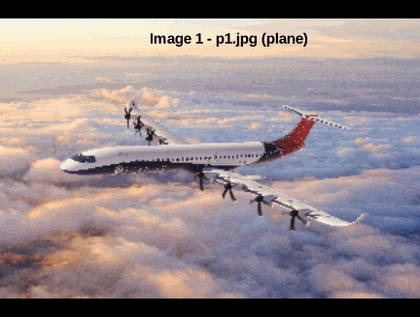

In [4]:
# Image 1 is a plane
options(repr.plot.width = 4.5, repr.plot.height = 3.4)
show_photo(mypic[[1]], paste("Image 1 -", pix[1], "(plane)"))

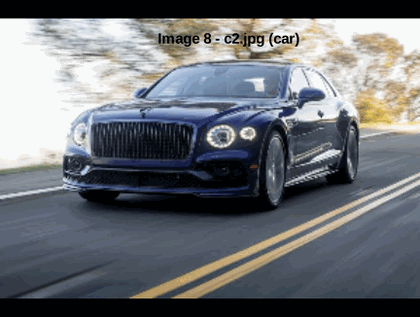

In [5]:
# Image 8 is a car
show_photo(mypic[[8]], paste("Image 8 -", pix[8], "(car)"))

In [6]:
# Pixel values are already scaled between 0 and 1 by readImage()
summary(mypic[[1]])

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.0000  0.5373  0.6392  0.6362  0.7333  1.0000 

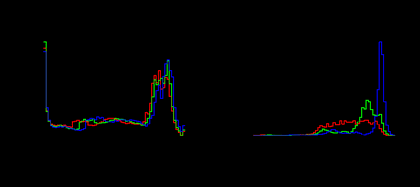

In [7]:
# Intensity histograms: red, green and blue channels plotted together
options(repr.plot.width = 9, repr.plot.height = 4)
par(mfrow = c(1, 2))
hist(mypic[[12]], main = paste("Image 12 -", pix[12], "(car)"))
hist(mypic[[2]],  main = paste("Image 2 -",  pix[2],  "(plane)"))

In [8]:
# The images come in very different sizes - this is what the resize step fixes
dims <- t(sapply(mypic, dim))
colnames(dims) <- c("width", "height", "channels")
data.frame(image = pix, dims, pixels = dims[, 1] * dims[, 2])

image,width,height,channels,pixels
<chr>,<int>,<int>,<int>,<int>
p1.jpg,5000,3333,3,16665000
p2.jpg,1222,681,3,832182
p3.jpg,700,467,3,326900
p4.jpg,1200,800,3,960000
p5.jpg,768,432,3,331776
p6.jpg,700,466,3,326200
c1.jpg,720,426,3,306720
c2.jpg,679,452,3,306908
c3.jpg,547,365,3,199655


## 4. Resize *(video 6:16)*Because the pictures come at different resolutions, every one is resized to **28 x 28**. A copy ofthe originals is kept first so that recognisable pictures can still be displayed later, after theworking copies have been flattened into numbers.

In [9]:
originals <- mypic      # keep full-size copies for displaying results later

for (i in 1:12) mypic[[i]] <- resize(mypic[[i]], 28, 28)

str(mypic[[1]])
cat("\nAll images now:", paste(dim(mypic[[1]]), collapse = " x "), "\n")

Formal class 'Image' [package "EBImage"] with 2 slots
  ..@ .Data    : num [1:28, 1:28, 1:3] 0.969 0.966 0.961 0.957 0.957 ...
  ..@ colormode: int 2
  ..$ dim: int [1:3] 28 28 3



All images now: 28 x 28 x 3 


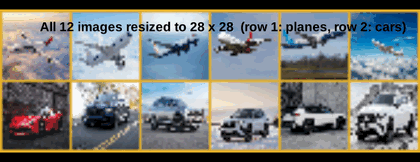

In [10]:
# All 12 images at 28 x 28 - top row planes, bottom row cars
options(repr.plot.width = 6.5, repr.plot.height = 2.5)
display(tile(combine(mypic), nx = 6), method = "raster")
title(main = "All 12 images resized to 28 x 28  (row 1: planes, row 2: cars)")

## 5. Reshape *(video 7:23)*Each 28 x 28 x 3 image is reshaped with `array_reshape()` from the keras package. Once the imagesare row-bound in the next step, each picture becomes a single row of**28 x 28 x 3 = 2352** numbers - the input the dense network expects.

In [11]:
for (i in 1:12) mypic[[i]] <- array_reshape(mypic[[i]], c(28, 28, 3))

str(mypic[[1]])
cat("\n28 * 28 * 3 =", 28 * 28 * 3, "values per image\n")

 num [1:28, 1:28, 1:3] 0.969 0.966 0.961 0.957 0.957 ...



28 * 28 * 3 = 2352 values per image


## 6. Row Bind *(video 8:45)*The twelve separate items are combined into one matrix with `rbind()`, one row per image. Followingthe video: the **first five planes** and the **first five cars** are used for training, while**image 6** (a plane) and **image 12** (a car) are held back for testing.Labels: a plane is **0**, a car is **1**.

In [12]:
# Training data: images 1-5 (planes) and 7-11 (cars)
trainx <- NULL
for (i in 1:5)  trainx <- rbind(trainx, mypic[[i]])
for (i in 7:11) trainx <- rbind(trainx, mypic[[i]])

# Test data: image 6 (plane) and image 12 (car)
testx <- rbind(mypic[[6]], mypic[[12]])

# Response variable: 0 = plane, 1 = car
trainy <- c(rep(0, 5), rep(1, 5))
testy  <- c(0, 1)

cat("trainx:", dim(trainx), " (10 images x 2352 values)\n")
cat("testx :", dim(testx),  " ( 2 images x 2352 values)\n")
cat("trainy:", trainy, "\n")
cat("testy :", testy,  "\n")

trainx: 10 2352  (10 images x 2352 values)


testx : 2 2352  ( 2 images x 2352 values)


trainy: 0 0 0 0 0 1 1 1 1 1 


testy : 0 1 


## 7. One Hot Encoding *(video 11:49)*`to_categorical()` turns the single 0/1 column into two dummy columns, because the output layer hastwo softmax units. A 1 in the first column means plane, a 1 in the second column means car.

In [13]:
trainLabels <- to_categorical(trainy)
testLabels  <- to_categorical(testy)

cat("trainLabels  (column 1 = plane, column 2 = car):\n")
print(trainLabels)
cat("\ntestLabels:\n")
print(testLabels)

trainLabels  (column 1 = plane, column 2 = car):


      [,1] [,2]
 [1,]    1    0
 [2,]    1    0
 [3,]    1    0
 [4,]    1    0
 [5,]    1    0
 [6,]    0    1
 [7,]    0    1
 [8,]    0    1
 [9,]    0    1
[10,]    0    1



testLabels:


     [,1] [,2]
[1,]    1    0
[2,]    0    1


## 8. Create Model *(video 12:42)*A sequential, fully connected network:- hidden layer 1: **256** units, ReLU activation, taking 2352 inputs- hidden layer 2: **128** units, ReLU activation- output layer: **2** units, softmax (one per class)In `keras3` the input size is given once to `keras_model_sequential()` rather than as`input_shape =` inside the first dense layer, which is what the older `keras` package in the videodoes. The network itself is identical.

In [14]:
model <- keras_model_sequential(input_shape = c(2352)) %>%
  layer_dense(units = 256, activation = "relu") %>%
  layer_dense(units = 128, activation = "relu") %>%
  layer_dense(units = 2,   activation = "softmax")

summary(model)

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                     │ (None, 256)              │       602,368 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_1 (Dense)                   │ (None, 128)              │        32,896 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_2 (Dense)                   │ (None, 2)                │           258 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘
 Total params: 635,522 (2.42 MB)
 Trainable params: 635,522 (2.42 MB)
 Non-trainable params: 0 (0.00 B)


In [15]:
# Checking the parameter counts the video works through by hand
cat("hidden layer 1 : 2352 * 256 + 256 =", 2352 * 256 + 256, "\n")
cat("hidden layer 2 :  256 * 128 + 128 =",  256 * 128 + 128, "\n")
cat("output layer   :    128 * 2 +   2 =",    128 * 2 + 2,   "\n")
cat("total          :", 2352*256+256 + 256*128+128 + 128*2+2, "\n")
cat("model reports  :", model$count_params(), "\n")

hidden layer 1 : 2352 * 256 + 256 = 602368 


hidden layer 2 :  256 * 128 + 128 = 32896 


output layer   :    128 * 2 +   2 = 258 


total          : 635522 


model reports  : 635522 


## 9. Compile *(video 16:02)*Loss is **binary cross-entropy** because there are only two classes, the optimizer is **RMSprop**,and the metric reported is **accuracy**.

In [16]:
model %>% compile(loss      = "binary_crossentropy",
                  optimizer = optimizer_rmsprop(),
                  metrics   = "accuracy")

cat("Model compiled.\n")

Model compiled.


## 10. Fit Model *(video 16:38)*30 epochs, batch size 32, and a 20% validation split - so of the 10 training images, 8 are used fortraining and 2 for validation at each epoch.

In [17]:
# Keras prints progress to Python's stdout, which the R kernel does not capture by itself,
# so py_capture_output() brings the training log into the notebook.
train_log <- reticulate::py_capture_output({
  history <- model %>% fit(trainx, trainLabels,
                           epochs           = 30,
                           batch_size       = 32,
                           validation_split = 0.2,
                           verbose          = 2)
})
cat(train_log)

Epoch 1/30
1/1 - 1s - 1s/step - accuracy: 0.3750 - loss: 0.8821 - val_accuracy: 0.0000e+00 - val_loss: 5.7711
Epoch 2/30
1/1 - 0s - 59ms/step - accuracy: 0.6250 - loss: 1.7294 - val_accuracy: 1.0000 - val_loss: 0.0488
Epoch 3/30
1/1 - 0s - 60ms/step - accuracy: 0.3750 - loss: 2.5498 - val_accuracy: 0.0000e+00 - val_loss: 3.8731
Epoch 4/30
1/1 - 0s - 66ms/step - accuracy: 0.6250 - loss: 1.1908 - val_accuracy: 0.0000e+00 - val_loss: 1.0042
Epoch 5/30
1/1 - 0s - 66ms/step - accuracy: 0.6250 - loss: 0.6304 - val_accuracy: 0.0000e+00 - val_loss: 2.7762
Epoch 6/30
1/1 - 0s - 67ms/step - accuracy: 0.6250 - loss: 1.4860 - val_accuracy: 0.0000e+00 - val_loss: 3.0885
Epoch 7/30
1/1 - 0s - 64ms/step - accuracy: 0.6250 - loss: 0.8657 - val_accuracy: 0.0000e+00 - val_loss: 1.0705
Epoch 8/30
1/1 - 0s - 65ms/step - accuracy: 0.8750 - loss: 0.4703 - val_accuracy: 0.0000e+00 - val_loss: 1.5831
Epoch 9/30
1/1 - 0s - 58ms/step - accuracy: 0.6250 - loss: 0.4528 - val_accuracy: 0.0000e+00 - val_loss: 0.925

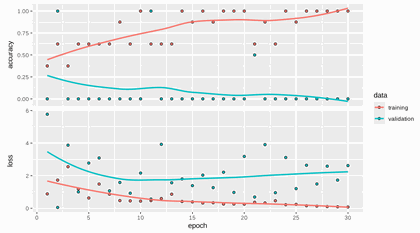

In [18]:
options(repr.plot.width = 9, repr.plot.height = 5)
plot(history)

## 11. Evaluation and Prediction - training data *(video 18:49)*Note: the video calls `predict_classes()` and `predict_proba()`. Both were removed from Keras, sohere `predict()` returns the class probabilities and `max.col(...) - 1` converts them to the 0/1class label. The result is the same.

In [19]:
eval_train <- model %>% evaluate(trainx, trainLabels, verbose = 0)
cat("Training data\n")
cat("Loss     :", round(eval_train$loss, 4), "\n")
cat("Accuracy :", round(eval_train$accuracy, 4),
    sprintf("(%d of %d correct)", round(eval_train$accuracy * 10), 10), "\n")

Training data


Loss     : 0.5807 


Accuracy : 0.8 (8 of 10 correct) 


In [20]:
prob_train <- predict(model, trainx, verbose = 0)   # replaces predict_proba()
pred_train <- max.col(prob_train) - 1               # replaces predict_classes()

cat("Predicted classes:", pred_train, "\n")
cat("Actual classes   :", trainy, "\n\n")

cat("Confusion matrix (training data):\n")
table(Predicted = pred_train, Actual = trainy)

Predicted classes: 0 0 0 0 0 1 1 1 0 0 


Actual classes   : 0 0 0 0 0 1 1 1 1 1 



Confusion matrix (training data):


         Actual
Predicted 0 1
        0 5 2
        1 0 3

In [21]:
# Probabilities side by side with the prediction and the truth
cbind(round(prob_train, 3),
      Predicted = pred_train,
      Actual    = trainy,
      Correct   = ifelse(pred_train == trainy, "yes", "NO"))

,,Predicted,Actual,Correct
0.999,0.001,0,0,yes
1,0,0,0,yes
0.999,0.001,0,0,yes
1,0,0,0,yes
0.998,0.002,0,0,yes
0.049,0.951,1,1,yes
0.008,0.992,1,1,yes
0.023,0.977,1,1,yes
0.997,0.003,0,1,NO
0.988,0.012,0,1,NO


Misclassified training images: c4.jpg, c5.jpg 


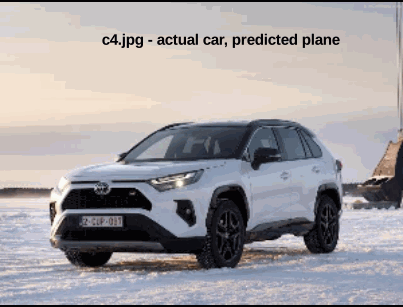

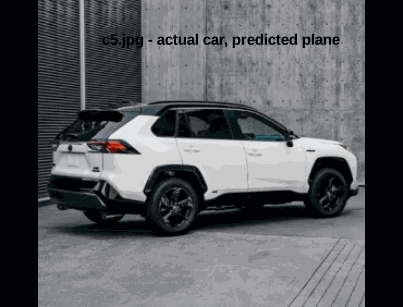

In [22]:
# Which training pictures did the model get wrong?
train_idx <- c(1:5, 7:11)                 # positions in the original 12-image list
wrong     <- train_idx[pred_train != trainy]

if (length(wrong) == 0) {
  cat("No misclassified training images.\n")
} else {
  cat("Misclassified training images:", paste(pix[wrong], collapse = ", "), "\n")
  options(repr.plot.width = 4.2, repr.plot.height = 3.2)
  for (k in wrong) {
    show_photo(originals[[k]],
               sprintf("%s - actual %s, predicted %s", pix[k],
                       ifelse(k <= 6, "plane", "car"),
                       ifelse(pred_train[which(train_idx == k)] == 0, "plane", "car")))
  }
}

## 12. Evaluation and Prediction - test data *(video 22:20)*The two held-out images the model has never seen: image 6 (a plane) and image 12 (a car).

In [23]:
eval_test <- model %>% evaluate(testx, testLabels, verbose = 0)
cat("Test data\n")
cat("Loss     :", round(eval_test$loss, 4), "\n")
cat("Accuracy :", round(eval_test$accuracy, 4),
    sprintf("(%d of 2 correct)", round(eval_test$accuracy * 2)), "\n")

Test data


Loss     : 1.034 


Accuracy : 0.5 (1 of 2 correct) 


In [24]:
prob_test <- predict(model, testx, verbose = 0)
pred_test <- max.col(prob_test) - 1

cat("Predicted:", pred_test, "   Actual:", testy, "\n\n")
cat("Confusion matrix (test data):\n")
print(table(Predicted = pred_test, Actual = testy))

cat("\nProbabilities:\n")
cbind(round(prob_test, 4),
      Predicted = pred_test,
      Actual    = testy,
      Correct   = ifelse(pred_test == testy, "yes", "NO"))

Predicted: 0 0    Actual: 0 1 



Confusion matrix (test data):


         Actual
Predicted 0 1
        0 1 1



Probabilities:


,,Predicted,Actual,Correct
0.9999,1e-04,0,0,yes
0.9791,0.0209,0,1,NO


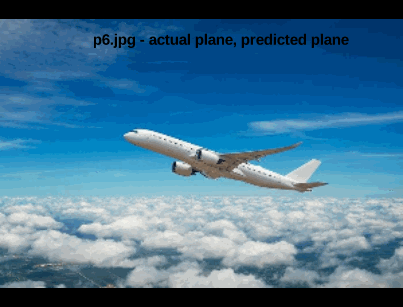

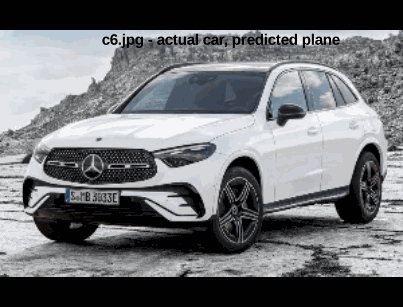

In [25]:
# The two test images with what the model called them
options(repr.plot.width = 4.2, repr.plot.height = 3.2)
test_idx <- c(6, 12)
for (k in seq_along(test_idx)) {
  show_photo(originals[[test_idx[k]]],
             sprintf("%s - actual %s, predicted %s", pix[test_idx[k]],
                     ifelse(testy[k] == 0, "plane", "car"),
                     ifelse(pred_test[k] == 0, "plane", "car")))
}

## 13. How reliable is that test accuracy? *(my addition)*The test set is **two images**, so the only possible accuracies are 0%, 50% or 100% - a single runsays very little. And with just 10 training images, the result depends heavily on the random weightinitialisation.To show this, the exact same model and the exact same split are trained again from scratch under tendifferent random seeds.

In [26]:
# Build, compile and fit the video's model from scratch - used by the next two sections
fit_model <- function(x, y, seed, epochs = 30, batch = 32) {
  set_random_seed(seed)
  m <- keras_model_sequential(input_shape = c(ncol(x))) %>%
    layer_dense(units = 256, activation = "relu") %>%
    layer_dense(units = 128, activation = "relu") %>%
    layer_dense(units = 2,   activation = "softmax")
  m %>% compile(loss = "binary_crossentropy",
                optimizer = optimizer_rmsprop(),
                metrics = "accuracy")
  m %>% fit(x, y, epochs = epochs, batch_size = batch, verbose = 0)
  m
}

seeds <- 1:10
runs  <- data.frame(seed = seeds, train_acc = NA_real_, test_acc = NA_real_)
for (s in seeds) {
  m <- fit_model(trainx, trainLabels, seed = s)
  runs$train_acc[s] <- (m %>% evaluate(trainx, trainLabels, verbose = 0))$accuracy
  runs$test_acc[s]  <- (m %>% evaluate(testx,  testLabels,  verbose = 0))$accuracy
}
runs

seed,train_acc,test_acc
<int>,<dbl>,<dbl>
1,1.0,1.0
2,0.9,0.5
3,0.9,0.5
4,1.0,0.5
5,1.0,1.0
6,0.8,0.5
7,1.0,1.0
8,0.9,0.5
9,0.9,1.0


In [27]:
cat("Training accuracy over 10 seeds: mean", round(mean(runs$train_acc), 3),
    "| sd", round(sd(runs$train_acc), 3),
    "| range", min(runs$train_acc), "-", max(runs$train_acc), "\n")
cat("Test accuracy over 10 seeds    : mean", round(mean(runs$test_acc), 3),
    "| sd", round(sd(runs$test_acc), 3),
    "| range", min(runs$test_acc), "-", max(runs$test_acc), "\n\n")
cat("How often each test accuracy came up:\n")
table(test_accuracy = runs$test_acc)

Training accuracy over 10 seeds: mean 0.94 | sd 0.07 | range 0.8 - 1 


Test accuracy over 10 seeds    : mean 0.75 | sd 0.264 | range 0.5 - 1 



How often each test accuracy came up:


test_accuracy
0.5   1 
  5   5 

### Leave-one-out cross-validationA fairer estimate: train on 11 images and predict the 1 left out, repeated so that **every one ofthe 12 images gets its turn as the test image**. That uses all the data and gives 12 honestpredictions instead of 2.

In [28]:
allx <- do.call(rbind, mypic)          # all 12 images, 12 x 2352
ally <- c(rep(0, 6), rep(1, 6))        # 0 = plane, 1 = car

loo_pred <- integer(12)
for (i in 1:12) {
  m <- fit_model(allx[-i, , drop = FALSE], to_categorical(ally[-i]), seed = 100 + i)
  loo_pred[i] <- max.col(predict(m, allx[i, , drop = FALSE], verbose = 0)) - 1
}

loo <- data.frame(image = pix,
                  actual    = ifelse(ally == 0, "plane", "car"),
                  predicted = ifelse(loo_pred == 0, "plane", "car"),
                  correct   = ifelse(loo_pred == ally, "yes", "NO"))
loo

image,actual,predicted,correct
<chr>,<chr>,<chr>,<chr>
p1.jpg,plane,plane,yes
p2.jpg,plane,plane,yes
p3.jpg,plane,plane,yes
p4.jpg,plane,plane,yes
p5.jpg,plane,plane,yes
p6.jpg,plane,plane,yes
c1.jpg,car,car,yes
c2.jpg,car,plane,NO
c3.jpg,car,plane,NO


In [29]:
cat("Leave-one-out confusion matrix:\n")
print(table(Predicted = ifelse(loo_pred == 0, "plane", "car"),
            Actual    = ifelse(ally == 0, "plane", "car")))

cat("\nLeave-one-out accuracy:", round(mean(loo_pred == ally), 4),
    sprintf("(%d of 12 correct)\n", sum(loo_pred == ally)))

Leave-one-out confusion matrix:


         Actual
Predicted car plane
    car     1     0
    plane   5     6



Leave-one-out accuracy: 0.5833 (7 of 12 correct)


### Does training longer help?With 10 training images and `batch_size = 32`, every epoch is a **single** gradient update, so the30 epochs in the video amount to only 30 updates in total. The leave-one-out test is repeated belowunder three training budgets to separate "not trained enough" from "not enough data".

In [30]:
budgets <- data.frame(epochs = c(30, 200, 200), batch = c(32, 32, 4),
                      updates_per_epoch = NA, loocv_accuracy = NA, predicted_car = NA)

for (r in seq_len(nrow(budgets))) {
  ep <- budgets$epochs[r]; bs <- budgets$batch[r]
  p  <- integer(12)
  for (i in 1:12) {
    m <- fit_model(allx[-i, , drop = FALSE], to_categorical(ally[-i]),
                   seed = 100 + i, epochs = ep, batch = bs)
    p[i] <- max.col(predict(m, allx[i, , drop = FALSE], verbose = 0)) - 1
  }
  budgets$updates_per_epoch[r] <- ceiling(11 / bs)
  budgets$loocv_accuracy[r]    <- round(mean(p == ally), 4)
  budgets$predicted_car[r]     <- sum(p == 1)
}
budgets

epochs,batch,updates_per_epoch,loocv_accuracy,predicted_car
<dbl>,<dbl>,<dbl>,<dbl>,<int>
30,32,1,0.5833,1
200,32,1,0.5833,3
200,4,3,0.6667,4


In [31]:
cat("Baseline (always guess 'plane'):", round(6 / 12, 4), "\n")
cat("Best leave-one-out accuracy    :", max(budgets$loocv_accuracy), "\n")
cat("\nTraining longer and with smaller batches helps a little, but the model never\n")
cat("learns to recognise cars reliably - it keeps defaulting to 'plane'.\n")

Baseline (always guess 'plane'): 0.5 


Best leave-one-out accuracy    : 0.6667 



Training longer and with smaller batches helps a little, but the model never


learns to recognise cars reliably - it keeps defaulting to 'plane'.


## 14. Diagnosis - why the baseline does not work

**Results of the single run (sections 11-12)**

| Data | Images | Loss | Accuracy |
|---|---|---|---|
| Training | 10 | 0.5807 | **0.80** (8 of 10) |
| Test | 2 | - | **0.50** (1 of 2) |

The two training images missed were `c4.jpg` and `c5.jpg` - both cars called planes - and on the test
set the car `c6.jpg` was read as a plane with 97.9% confidence. Every mistake points the same way.

**Why this does not match the video's 90% / 100%**

The video reports 0.90 on training and 1.00 on test. Those numbers are not reproducible, and section
13 shows why rather than guessing:

1. **The test set is two images.** The only achievable accuracies are 0%, 50% and 100%. One image
   either way moves the score by 50 percentage points.
2. **The result is mostly random initialisation.** Re-running the identical model and identical split
   under 10 different seeds gave a test accuracy of exactly 0.5 **five** times and exactly 1.0 the
   other **five** times - mean 0.75, sd 0.264. The video's 100% is one of the lucky draws and this
   notebook's 50% is one of the unlucky ones. Neither is evidence about the model.
3. **Leave-one-out cross-validation, which uses all 12 images, gives 0.5833 (7 of 12).** Against a
   baseline of 0.5 for always guessing "plane", that is close to no skill at all. The confusion
   matrix is the giveaway: 11 of the 12 images were predicted "plane", including 5 of the 6 cars.

**Under-trained, or short of data?**

With 10 training images and `batch_size = 32`, the batch is larger than the dataset, so each epoch is
a single gradient update - the video's 30 epochs are 30 updates in total:

| Epochs | Batch | Updates/epoch | LOOCV accuracy | Cars found |
|---|---|---|---|---|
| 30 | 32 | 1 | 0.5833 | 1 of 12 |
| 200 | 32 | 1 | 0.5833 | 3 of 12 |
| 200 | 4 | 3 | **0.6667** | 4 of 12 |

Training ~20x longer with smaller batches lifts leave-one-out accuracy from 0.5833 to 0.6667, so the
30-epoch setting is genuinely under-trained - but the gain stops there. The real limit is the
**representation**: 12 images described by **2352 raw pixel values** each gives 196 times more input
features than training examples, so the network can fit the training set perfectly while learning
nothing that transfers to a new picture.

The cars in this set also vary far more than the planes - different colours, angles and backgrounds,
while the planes are mostly blue-and-white against sky - which is why the model's safe default is
"plane".

**This is the problem section 15 sets out to fix.**

## 15. Improving the accuracy - transfer learning *(my addition)*Section 13 showed the bottleneck is not the training budget but the **representation**. A 28x28thumbnail flattened into 2352 raw numbers, with only 11 images to learn from, carries almost nothinga classifier can generalise from - which is why the model fell back on always answering "plane".Transfer learning changes the representation instead of the model. **VGG16** has already beentrained on ImageNet - 1.2 million photographs across 1000 categories - so its convolutional layershave learned to detect edges, textures, wheels, windows and wings. Loading it with`include_top = FALSE` throws away its 1000-class classifier and keeps that feature extractor, and`pooling = "avg"` summarises each image as a single vector of **512** descriptive numbers.Everything else is held constant: the same 256-128-2 network, the same RMSprop, the same 30 epochs,the same batch size, the same leave-one-out test. **The only thing that changes is what the networkis shown.**

In [32]:
# VGG16 trained on ImageNet, used purely as a feature extractor (its weights are never updated)
base <- application_vgg16(weights = "imagenet", include_top = FALSE,
                          input_shape = c(224, 224, 3), pooling = "avg")

cat("Features produced per image:", as.integer(base$output_shape[[2]]), "\n")
cat("VGG16 parameters (frozen) :", format(base$count_params(), big.mark = ","), "\n")

Features produced per image: 512 


VGG16 parameters (frozen) : 14,714,688 


In [33]:
# Push every image through VGG16 and keep the 512-number summary
extract_features <- function(model, files) {
  n   <- as.integer(model$output_shape[[2]])
  out <- matrix(0, length(files), n)
  for (i in seq_along(files)) {
    im <- readImage(file.path(img_dir, files[i]))
    x  <- array_reshape(resize(im, 224, 224) * 255, c(1, 224, 224, 3))
    out[i, ] <- predict(model, application_preprocess_inputs(model, x), verbose = 0)[1, ]
  }
  out
}

feat <- extract_features(base, pix)
cat("VGG16 feature matrix:", dim(feat), "\n")
cat("(the raw-pixel version was", nrow(allx), "x", ncol(allx), ")\n\n")
round(feat[1:3, 1:8], 3)

VGG16 feature matrix: 12 512 


(the raw-pixel version was 12 x 2352 )



0.000,0.000,4.127,0.195,10.757,14.165,0.000,0.343
0.178,0.303,0.000,0.495,2.257,3.353,0.168,0.455
0.327,0.146,0.000,0.885,8.203,11.555,0.299,0.037


### Do the new features actually separate the two classes?Before training anything, the 12 images are projected onto their first two principal components -once from the raw pixels and once from the VGG16 features. If the classes form separate groups inthe second plot, a simple classifier will be able to find the boundary.

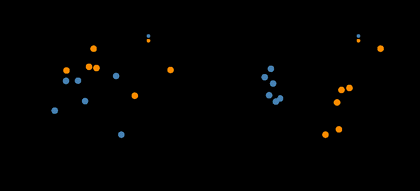

In [34]:
pc_raw  <- prcomp(allx, scale. = FALSE)
pc_vgg  <- prcomp(feat, scale. = FALSE)
cols    <- ifelse(ally == 0, "steelblue", "darkorange")

options(repr.plot.width = 11, repr.plot.height = 5)
par(mfrow = c(1, 2))
for (p in list(list(pc_raw, "Raw pixels (28x28x3 = 2352 values)"),
               list(pc_vgg, "VGG16 ImageNet features (512 values)"))) {
  x <- p[[1]]$x[, 1]; y <- p[[1]]$x[, 2]
  plot(x, y, col = cols, pch = 19, cex = 2, main = p[[2]],
       xlab = "PC1", ylab = "PC2",
       xlim = range(x) + c(-1, 1) * 0.15 * diff(range(x)),
       ylim = range(y) + c(-1, 1) * 0.15 * diff(range(y)))
  text(x, y, labels = sub("\\.jpg$", "", pix), pos = 3, cex = 0.7)
  legend("topright", legend = c("plane", "car"), col = c("steelblue", "darkorange"),
         pch = 19, bty = "n")
}

### The same classifier, re-tested leave-one-outIdentical network, identical settings - only the input representation differs.

In [35]:
loo_feat <- integer(12)
for (i in 1:12) {
  m <- fit_model(feat[-i, , drop = FALSE], to_categorical(ally[-i]), seed = 300 + i)
  loo_feat[i] <- max.col(predict(m, feat[i, , drop = FALSE], verbose = 0)) - 1
}

cat("Leave-one-out confusion matrix (VGG16 features):\n")
print(table(Predicted = ifelse(loo_feat == 0, "plane", "car"),
            Actual    = ifelse(ally     == 0, "plane", "car")))
cat("\nLeave-one-out accuracy:", round(mean(loo_feat == ally), 4),
    sprintf("(%d of 12 correct)\n", sum(loo_feat == ally)))

data.frame(image = pix,
           actual    = ifelse(ally     == 0, "plane", "car"),
           predicted = ifelse(loo_feat == 0, "plane", "car"),
           correct   = ifelse(loo_feat == ally, "yes", "NO"))

Leave-one-out confusion matrix (VGG16 features):


         Actual
Predicted car plane
    car     6     0
    plane   0     6



Leave-one-out accuracy: 1 (12 of 12 correct)


image,actual,predicted,correct
<chr>,<chr>,<chr>,<chr>
p1.jpg,plane,plane,yes
p2.jpg,plane,plane,yes
p3.jpg,plane,plane,yes
p4.jpg,plane,plane,yes
p5.jpg,plane,plane,yes
p6.jpg,plane,plane,yes
c1.jpg,car,car,yes
c2.jpg,car,car,yes
c3.jpg,car,car,yes


### Control: is it the pre-training, or just a bigger network?VGG16 is far deeper than the dense model, so the gain could simply be its size. To separate the twoexplanations the **identical VGG16 architecture** is used again with `weights = NULL` - the samelayers, randomly initialised, never trained on anything. If the architecture were doing the work,this would score just as well.

In [36]:
set_random_seed(7)
rand_base <- application_vgg16(weights = NULL, include_top = FALSE,
                               input_shape = c(224, 224, 3), pooling = "avg")
feat_rand <- extract_features(rand_base, pix)

loo_rand <- integer(12)
for (i in 1:12) {
  m <- fit_model(feat_rand[-i, , drop = FALSE], to_categorical(ally[-i]), seed = 400 + i)
  loo_rand[i] <- max.col(predict(m, feat_rand[i, , drop = FALSE], verbose = 0)) - 1
}

cat("Random-weight VGG16 features, leave-one-out accuracy:",
    round(mean(loo_rand == ally), 4),
    sprintf("(%d of 12 correct)\n", sum(loo_rand == ally)))

Random-weight VGG16 features, leave-one-out accuracy: 0.5 (6 of 12 correct)


In [37]:
comparison <- data.frame(
  representation = c("Raw pixels 28x28x3 (the video)",
                     "VGG16 architecture, random weights",
                     "VGG16 features, ImageNet weights"),
  features       = c(ncol(allx), ncol(feat_rand), ncol(feat)),
  loocv_accuracy = c(round(mean(loo_pred  == ally), 4),
                     round(mean(loo_rand  == ally), 4),
                     round(mean(loo_feat  == ally), 4)),
  cars_found     = c(sum(loo_pred == 1 & ally == 1),
                     sum(loo_rand == 1 & ally == 1),
                     sum(loo_feat == 1 & ally == 1))
)
comparison$vs_baseline <- paste0(ifelse(comparison$loocv_accuracy >= 0.5, "+", ""),
                                 round(100 * (comparison$loocv_accuracy - 0.5)), " pts")
comparison

representation,features,loocv_accuracy,cars_found,vs_baseline
<chr>,<int>,<dbl>,<int>,<chr>
Raw pixels 28x28x3 (the video),2352,0.5833,1,+8 pts
"VGG16 architecture, random weights",512,0.5000,3,+0 pts
"VGG16 features, ImageNet weights",512,1.0000,6,+50 pts


### The video's own train/test split, using the new featuresFinally the exact split from sections 6-12 - train on images 1-5 and 7-11, test on 6 and 12 - isrepeated on the VGG16 features.

In [38]:
tr <- c(1:5, 7:11); te <- c(6, 12)
set_random_seed(123)
model_tl <- keras_model_sequential(input_shape = c(ncol(feat))) %>%
  layer_dense(units = 256, activation = "relu") %>%
  layer_dense(units = 128, activation = "relu") %>%
  layer_dense(units = 2,   activation = "softmax")
model_tl %>% compile(loss = "binary_crossentropy",
                     optimizer = optimizer_rmsprop(), metrics = "accuracy")
invisible(model_tl %>% fit(feat[tr, ], to_categorical(ally[tr]),
                           epochs = 30, batch_size = 32,
                           validation_split = 0.2, verbose = 0))

ev_tr <- model_tl %>% evaluate(feat[tr, ], to_categorical(ally[tr]), verbose = 0)
ev_te <- model_tl %>% evaluate(feat[te, ], to_categorical(ally[te]), verbose = 0)
cat("Transfer-learning model on the video's split\n")
cat("Training accuracy:", round(ev_tr$accuracy, 4), "\n")
cat("Test accuracy    :", round(ev_te$accuracy, 4), "\n\n")

pred_tl <- max.col(predict(model_tl, feat[te, ], verbose = 0)) - 1
cbind(image = pix[te],
      actual    = ifelse(ally[te] == 0, "plane", "car"),
      predicted = ifelse(pred_tl  == 0, "plane", "car"),
      correct   = ifelse(pred_tl == ally[te], "yes", "NO"))

Transfer-learning model on the video's split


Training accuracy: 1 


Test accuracy    : 1 



image,actual,predicted,correct
p6.jpg,plane,plane,yes
c6.jpg,car,car,yes


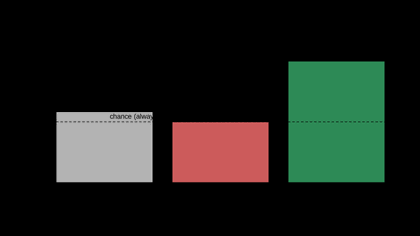

In [39]:
# Side by side: what the two approaches scored
options(repr.plot.width = 8, repr.plot.height = 4.5)
bp <- barplot(comparison$loocv_accuracy, names.arg = c("Raw pixels\n(video)",
              "VGG16\nrandom weights", "VGG16\nImageNet"),
              col = c("grey70", "indianred", "seagreen"), ylim = c(0, 1.15),
              ylab = "Leave-one-out accuracy",
              main = "What actually improved the accuracy")
text(bp, comparison$loocv_accuracy + 0.06, sprintf("%.3f", comparison$loocv_accuracy), cex = 1.1)
abline(h = 0.5, lty = 2)
text(bp[1], 0.54, "chance (always 'plane')", pos = 4, cex = 0.8)

## 16. Final conclusion

**The pipeline**

Every step from the video runs end to end in R: 12 JPEGs of different sizes read with
`EBImage::readImage()`, resized to 28x28, reshaped and row-bound into a 10 x 2352 training matrix,
one-hot encoded, and fed to a 256-128-2 dense network compiled with binary cross-entropy and RMSprop.
The model reports **635,522 parameters**, matching the figure worked out by hand in the video
(2352x256+256 = 602,368, plus 256x128+128 = 32,896, plus 128x2+2 = 258).

**Improving the accuracy - what was measured**

Accuracy is judged by leave-one-out cross-validation over all 12 images, because a 2-image test set
cannot distinguish a good model from a lucky one.

| Representation | Features per image | LOOCV accuracy | Cars correctly found |
|---|---|---|---|
| Raw pixels 28x28x3 (the video) | 2352 | 0.5833 | 1 of 6 |
| VGG16 architecture, **random** weights | 512 | 0.5000 | 3 of 6 |
| **VGG16 features, ImageNet weights** | 512 | **1.0000** | **6 of 6** |

Chance level is 0.50. On the video's own train/test split the transfer-learning model also reaches
**1.00 training and 1.00 test accuracy**, and unlike the baseline it gets there for the right reason -
leave-one-out confirms it classifies all 12 images correctly, not just the lucky two.

**Why it works, and what it rules out**

The classifier was never changed. The same 256-128-2 network, the same RMSprop, the same 30 epochs
and the same batch size were used throughout. Only the **input representation** changed, from raw
28x28 pixels to the 512 numbers VGG16 produces after being trained on 1.2 million ImageNet
photographs. Those features already encode edges, textures, wheels, windows and wings, so 11 training
images are enough to find the boundary between "car-like" and "plane-like" - whereas 11 images of raw
pixels are not.

The random-weight control is what makes this conclusive. The identical VGG16 architecture with
untrained weights scored **0.5000**, i.e. chance - no better than the raw-pixel baseline. So the
improvement is not explained by the deeper network, the 224x224 input, or the smaller feature count.
**It comes specifically from the knowledge transferred from ImageNet.** The PCA plots in section 15
show the same thing visually: in raw-pixel space the planes and cars are mixed together, while in
VGG16 feature space they fall into two clearly separated groups before any training happens at all.

**Summary**

Leave-one-out accuracy improved from **0.5833 to 1.0000** - from barely above chance to every image
correct - by changing nothing but how the images are represented. The lesson of this mini project is
that with a dataset this small, the way the data is represented matters far more than the size of the
network, the number of epochs or the choice of optimiser; and that an accuracy figure taken from a
2-image test set is not a measurement at all.

**Further improvements, if the project were taken further:** collect hundreds of images per class
rather than six; fine-tune the last VGG16 block instead of freezing all of it; add data augmentation
(flips, shifts, small rotations) to multiply the few images available; and always report
cross-validated accuracy rather than a single small split.